# Evaluation File
This file is used to plot Confusion matrix and
<b>perform model evaluation</b>
# This file contain ("VALIDation Section")
Validation is used for training
# And also ("Test Data Section")
Test data is simulate real life situation

In [1]:
import os
import shutil
import torch
import torch.nn as nn 
from torch.utils.data import DataLoader
from torch.utils.data import Subset, random_split 
from torchvision import datasets, transforms, models
from torch.optim import AdamW 
from tqdm import tqdm
from torch.cuda import amp
from torch.utils.data import Dataset
import json
from PIL import Image
from torchvision import datasets, transforms
import kagglehub

from torch.optim.lr_scheduler import CosineAnnealingLR 
import matplotlib.pyplot as plt 
import torchvision.transforms.functional as F 

from sklearn.metrics import confusion_matrix
import seaborn as sns

from torch import autocast 
from torch.amp import GradScaler
import numpy as np

PROJECT_ROOT = os.getcwd()

DATA_DIR = os.path.join(PROJECT_ROOT, "data", "flower_data")
TRAIN_DIR = os.path.join(DATA_DIR, "train")
VALID_DIR = os.path.join(DATA_DIR, "valid")
TEST_DIR  = os.path.join(DATA_DIR, "test")
os.makedirs(DATA_DIR, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)

NUM_CLASSES = 102
BATCH_SIZE = 32 
ACCUMULATION_STEPS = 4
NUM_EPOCHS = 100 
LEARNING_RATE = 3e-4 
WEIGHT_DECAY = 1e-4 
NUM_WORKERS = 8 
MODEL_ARCHITECTURE = "Resnet50"

SAVE_DIR = os.path.join(PROJECT_ROOT, "checkpoints")
os.makedirs(SAVE_DIR, exist_ok=True)

C:\Users\chuaw\anaconda3\envs\DLSem3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: C:\Users\chuaw\Projects\DLSem3_Assignment1
Data directory: C:\Users\chuaw\Projects\DLSem3_Assignment1\data\flower_data


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [3]:
# Load cat_to_name mapping
with open(os.path.join(DATA_DIR, "cat_to_name.json"), "r") as f:
    cat_to_name = json.load(f)

# Transforms
transform_train_data = transforms.Compose([
    transforms.RandomRotation(30),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], # this value is not random, check my explaination
                         [0.229, 0.224, 0.225]) # this value is not random...
])
transform_valid_test_data = transforms.Compose([
    transforms.Resize(255), #first make it bigger
    transforms.CenterCrop(224), # and then crop it so that we dont lose data
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], #this will normalize the valid data as well
                         [0.229, 0.224, 0.225])
])
class TestDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        # List all image files
        self.image_files = sorted([f for f in os.listdir(root_dir)
                                   if f.lower().endswith(('.png', '.jpg', '.jpeg'))])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.image_files[idx])
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        # Return image and filename (no label)
        return image, self.image_files[idx]

# Datasets

# train_dataset = datasets.ImageFolder(root=os.path.join(DATA_DIR, "train"), transform=transform) #this is the old, transform = transform
train_dataset = datasets.ImageFolder(root=os.path.join(DATA_DIR, "train"), transform = transform_train_data)
valid_dataset = datasets.ImageFolder(root=os.path.join(DATA_DIR, "valid"), transform=transform_valid_test_data)
test_dataset = TestDataset(root_dir=os.path.join(DATA_DIR, "test"), transform=transform_valid_test_data)

In [4]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

def decode_label(label):
    folder_name = train_dataset.classes[label]  
    return cat_to_name.get(folder_name, folder_name)

print(f"Number of classes: {len(train_dataset.classes)}")
print(f"First 5 class names: {[decode_label(i) for i in range(5)]}")
print(f"Training samples: {len(train_dataset)}")
print(f"The following is test images")
for images, filenames in test_loader:
    print(filenames)  
    break

Number of classes: 102
First 5 class names: ['pink primrose', 'globe thistle', 'blanket flower', 'trumpet creeper', 'blackberry lily']
Training samples: 6552
The following is test images
('image_00005.jpg', 'image_00006.jpg', 'image_00024.jpg', 'image_00025.jpg', 'image_00029.jpg', 'image_00050.jpg', 'image_00060.jpg', 'image_00065.jpg', 'image_00092.jpg', 'image_00099.jpg', 'image_00114.jpg', 'image_00116.jpg', 'image_00132.jpg', 'image_00176.jpg', 'image_00177.jpg', 'image_00187.jpg', 'image_00191.jpg', 'image_00202.jpg', 'image_00203.jpg', 'image_00204.jpg', 'image_00212.jpg', 'image_00222.jpg', 'image_00239.jpg', 'image_00248.jpg', 'image_00251.jpg', 'image_00258.jpg', 'image_00260.jpg', 'image_00277.jpg', 'image_00282.jpg', 'image_00284.jpg', 'image_00288.jpg', 'image_00291.jpg')


# For evaluation of 5 random classes (E.g. confusion matrix, accuracy)


In [5]:
import random
import numpy as np

# seed for consistency
random.seed(42)
np.random.seed(42)

all_class_indices = list(range(len(valid_dataset.classes)))

#random select 5 classes, use sorted to keep consistency (eg random 1 - 100)
chosen_global_indices = sorted(random.sample(all_class_indices, 5))

#readable name from json file , because original name is in number
chosen_class_names = [valid_dataset.classes[i] for i in chosen_global_indices]
chosen_readable_names = [cat_to_name.get(name, name) for name in chosen_class_names]

print(f"Randomly selected 5 classes : {chosen_global_indices}")
print(f"Class names: {chosen_readable_names}")

# This is for creating the new 5x5 matrix
global_to_local_map = {global_idx: local_idx for local_idx, global_idx in enumerate(chosen_global_indices)}

# 5.
subset_sample_indices = [i for i, target in enumerate(valid_dataset.targets) if target in chosen_global_indices]

# 6. 
five_class_subset = Subset(valid_dataset, subset_sample_indices)

# 7. 
five_class_valid_loader = DataLoader(five_class_subset, batch_size=BATCH_SIZE)

print(f"Created 5-class validation subset:  {len(five_class_subset)} samples.")

Randomly selected 5 classes : [3, 14, 35, 81, 94]
Class names: ['trumpet creeper', 'hard-leaved pocket orchid', 'siam tulip', 'anthurium', 'bee balm']
Created 5-class validation subset:  28 samples.


In [6]:
print("Building (ResNet50) model...")
def build_model(num_classes, pretrained=True, freeze_backbone=True):
    model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if pretrained else None)
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)

    if freeze_backbone:
        for name, param in model.named_parameters():
            if "fc" not in name:
                param.requires_grad = False

    return model.to(device)

Building (ResNet50) model...


In [7]:
criterion = nn.CrossEntropyLoss()
scaler = GradScaler()

# lets evaluate the accuracy on "5 random class <FROM< 102 CLASS"

--- Loading checkpoint: best_model_checkpoint_fresh.pth ---



C:\Users\chuaw\AppData\Local\Temp\ipykernel_3460\2397713634.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(CHECKPOINT_FILENAME, map_location=dev

Model, weights, and mappings loaded successfully.

--- Evaluating on the 5-Class Validation set ---


Predicting on 5-Class Validation: 100%|██████████████████████████████████████████████████| 1/1 [00:00<00:00,  2.30it/s]


Final 5-Class Validation Accuracy: 96.43%

Remap predictions for 5x5 Confusion Matrix
5x5 CM shape: (5, 5)
False Negatives mapped to 'other' classes: [0 0 0 1 0]
brewing 5x5 matrix


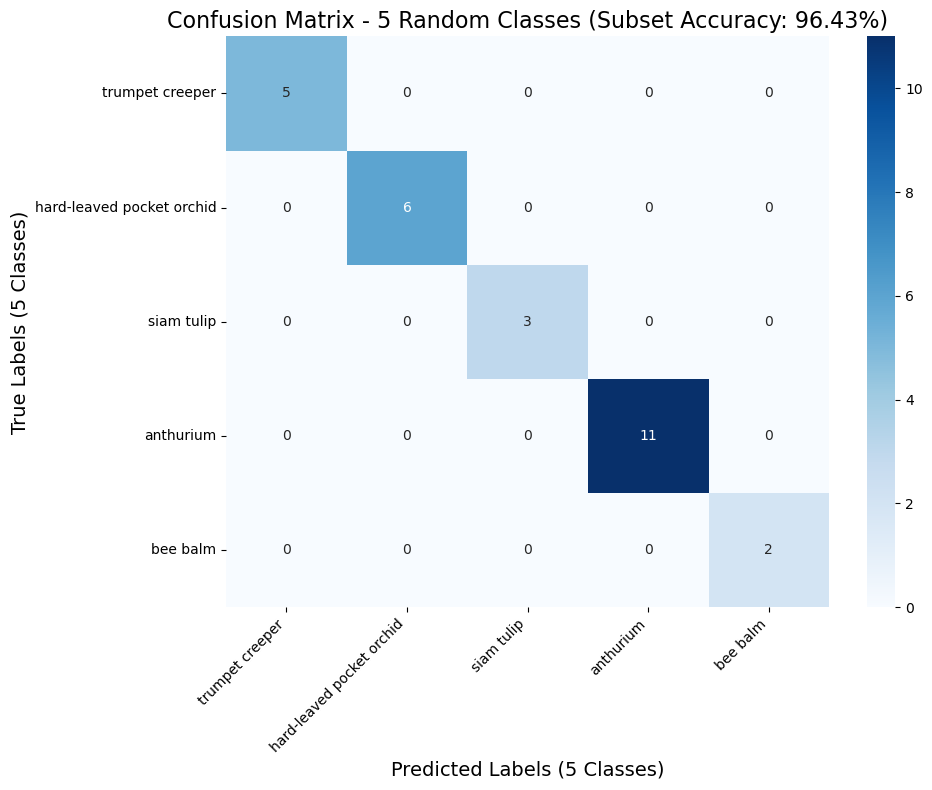

In [8]:
CHECKPOINT_FILENAME = 'best_model_checkpoint_fresh.pth'

print(f"--- Loading checkpoint: {CHECKPOINT_FILENAME} ---\n")
try:
    checkpoint = torch.load(CHECKPOINT_FILENAME, map_location=device) 
except Exception as e:
    print(f"Error loading checkpoint: {e}")

model = build_model(num_classes=NUM_CLASSES, freeze_backbone=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.to(device)
model.eval()

class_to_idx = checkpoint['class_to_idx']
cat_to_name = checkpoint['cat_to_name']
print("Model, weights, and mappings loaded successfully.")

def evaluate_model(data_loader, dataset_name, checkpoint_filename):
    all_preds = []
    all_labels = []
    correct = 0
    total = 0
    
    print(f"\n--- Evaluating on the {dataset_name} set ---")

    with torch.no_grad():
        for images, labels in tqdm(data_loader, desc=f"Predicting on {dataset_name}"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            
            _, preds = torch.max(outputs, 1)
            
            # For accuracy calculation (compares global pred 0-101 vs global label 0-101)
            total += labels.size(0)
            correct += (preds == labels).sum().item()
            
            # For confusion matrix (store global indices)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    accuracy = 100 * correct / total
    print(f"Final {dataset_name} Accuracy: {accuracy:.2f}%\n")
    
    return all_labels, all_preds, accuracy

val_labels_global, val_preds_global, val_acc = evaluate_model(five_class_valid_loader, "5-Class Validation", CHECKPOINT_FILENAME)


print("Remap predictions for 5x5 Confusion Matrix")

local_labels = [global_to_local_map[g_label] for g_label in val_labels_global]

local_preds = [global_to_local_map.get(p_label, -1) for p_label in val_preds_global]

full_local_labels_list = list(range(5)) + [-1]
cm_full = confusion_matrix(local_labels, local_preds, labels=full_local_labels_list)

# This is the 5x5 matrix for plotting (ignore the "other" column)
cm = cm_full[0:5, 0:5] 

# This (1x5) array stores the predictions that were "False Negatives" to the "other" 97 classes
fn_to_other = cm_full[0:5, 5] 

print(f"5x5 CM shape: {cm.shape}")
print(f"False Negatives mapped to 'other' classes: {fn_to_other}")

# Set the readable names for the plot
readable_names = chosen_readable_names

# plotting 5x5 matrix
print(f"brewing 5x5 matrix")
plt.figure(figsize=(10, 8)) # Smaller figure size for 5x5
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=readable_names, 
            yticklabels=readable_names)

plt.xlabel("Predicted Labels (5 Classes)", fontsize=14)
plt.ylabel("True Labels (5 Classes)", fontsize=14)
# Note: val_acc is the *actual* accuracy on this subset, which is what we want.
plt.title(f"Confusion Matrix - 5 Random Classes (Subset Accuracy: {val_acc:.2f}%)", fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig("confusion_matrix_5class.png")
plt.show()

Calculating overall performance metrics for the 5-class subset...
--- Generating Overall (Macro-Averaged) 2x2 Confusion Matrix (5-Class Subset) ---


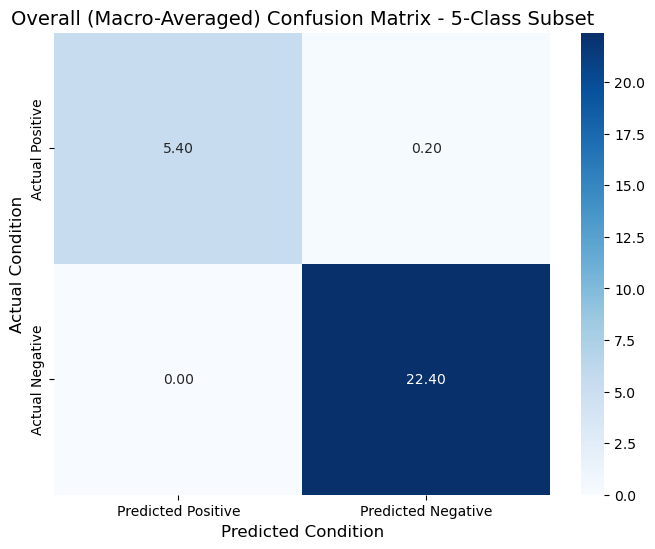


Average TP per class: 5.40

Average FP   per class: 0.00

Average TN per class: 22.40

Average FN per class: 0.20


In [9]:
print("Calculating overall performance metrics for the 5-class subset...")

TP = 0
FP = 0
TN = 0
FN = 0

num_classes = cm.shape[0] # This is 5
total_samples = len(local_labels) # This is the true total (e.g., 818)

for i in range(num_classes):
    # True Positives (TP): correctly predicted = class i
    TP_i = cm[i, i]
    
    # False Positives (FP): Incorrectly predicted = class i (sum column i, minus TP_i)
    FP_i = cm[:, i].sum() - TP_i
    
    # False Negatives (FN): Class i was predicted as something else
    # This is (FNs to other 4 classes) + (FNs to other 97 classes)
    FN_i = (cm[i, :].sum() - TP_i) + fn_to_other[i]
    
    # True Negatives (TN): All samples not in classi , and then correctly predicted as not class i
    TN_i = total_samples - (TP_i + FP_i + FN_i)
    
    # Sum up for the overall counts ( all 5 classes)
    TP += TP_i
    FP += FP_i
    TN += TN_i
    FN += FN_i

# calc average values per class for the 2x2 matrix
avg_TP = TP / num_classes
avg_FP = FP / num_classes
avg_TN = TN / num_classes
avg_FN = FN / num_classes

# Create the 2x2 matrix data using the "average" values
overall_cm_avg = np.array([[avg_TP, avg_FN], [avg_FP, avg_TN]])

print("--- Generating Overall (Macro-Averaged) 2x2 Confusion Matrix (5-Class Subset) ---")

plt.figure(figsize=(8, 6))
sns.heatmap(overall_cm_avg, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=['Predicted Positive', 'Predicted Negative'],
            yticklabels=['Actual Positive', 'Actual Negative'])

plt.xlabel("Predicted Condition", fontsize=12)
plt.ylabel("Actual Condition", fontsize=12)
plt.title("Overall (Macro-Averaged) Confusion Matrix - 5-Class Subset", fontsize=14)
plt.savefig("confusion_matrix_overall_2x2_5class.png")
plt.show()

print(f"\nAverage TP per class: {avg_TP:.2f}")
print(f"\nAverage FP   per class: {avg_FP:.2f}")
print(f"\nAverage TN per class: {avg_TN:.2f}")
print(f"\nAverage FN per class: {avg_FN:.2f}")

Calculating overall performance metrics for the 5-class subset...
--- Generating Overall (Macro-Averaged) 2x2 Confusion Matrix (5-Class Subset) ---


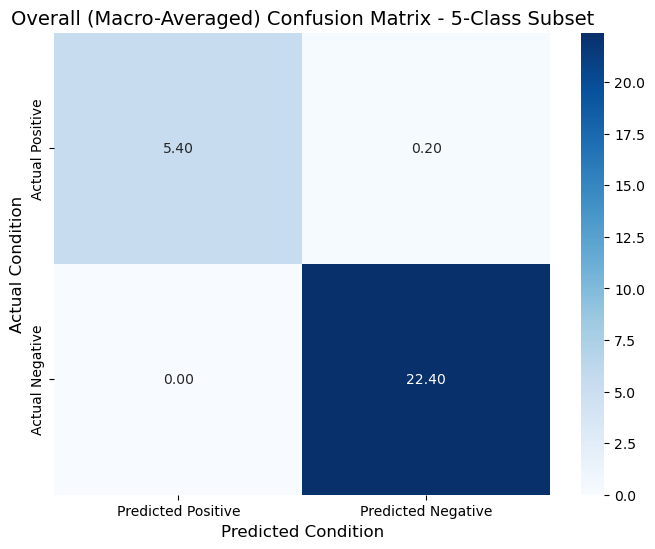


Average TP per class: 5.40
Average FP per class: 0.00
Average TN per class: 22.40
Average FN per class: 0.20


In [10]:
print("Calculating overall performance metrics for the 5-class subset...")

TP = 0
FP = 0
TN = 0
FN = 0

num_classes = 5
total_samples = len(local_labels) # This is the true total (e.g., 818)

for i in range(num_classes):
    # True Positives (TP): Correctly predicted as class i
    TP_i = cm[i, i]
    
    # False Positives (FP): Incorrectly predicted as class i (sum column i, minus TP_i)
    FP_i = cm[:, i].sum() - TP_i
    
    # False Negatives (FN): Class i was predicted as something else
    # This is (FNs to other 4 classes) + (FNs to other 97 classes)
    FN_i = (cm[i, :].sum() - TP_i) + fn_to_other[i]
    
    # True Negatives (TN): All samples not in class i, correctly predicted as not class i
    TN_i = total_samples - (TP_i + FP_i + FN_i)
    
    # Sum up for the overall counts (across all 5 classes)
    TP += TP_i
    FP += FP_i
    TN += TN_i
    FN += FN_i

# Calculate the average values per class for the 2x2 matrix
avg_TP = TP / num_classes
avg_FP = FP / num_classes
avg_TN = TN / num_classes
avg_FN = FN / num_classes

# Create the 2x2 matrix data using the *average* values
overall_cm_avg = np.array([[avg_TP, avg_FN], [avg_FP, avg_TN]])

print("--- Generating Overall (Macro-Averaged) 2x2 Confusion Matrix (5-Class Subset) ---")

plt.figure(figsize=(8, 6))
sns.heatmap(overall_cm_avg, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=['Predicted Positive', 'Predicted Negative'],
            yticklabels=['Actual Positive', 'Actual Negative'])

plt.xlabel("Predicted Condition", fontsize=12)
plt.ylabel("Actual Condition", fontsize=12)
plt.title("Overall (Macro-Averaged) Confusion Matrix - 5-Class Subset", fontsize=14)
plt.savefig("confusion_matrix_overall_2x2_5class.png")
plt.show()

print(f"\nAverage TP per class: {avg_TP:.2f}")
print(f"Average FP per class: {avg_FP:.2f}")
print(f"Average TN per class: {avg_TN:.2f}")
print(f"Average FN per class: {avg_FN:.2f}")

Calculat overall performance metrics
--- Generating Overall (Macro-Averaged) 2x2 Confusion Matrix ---


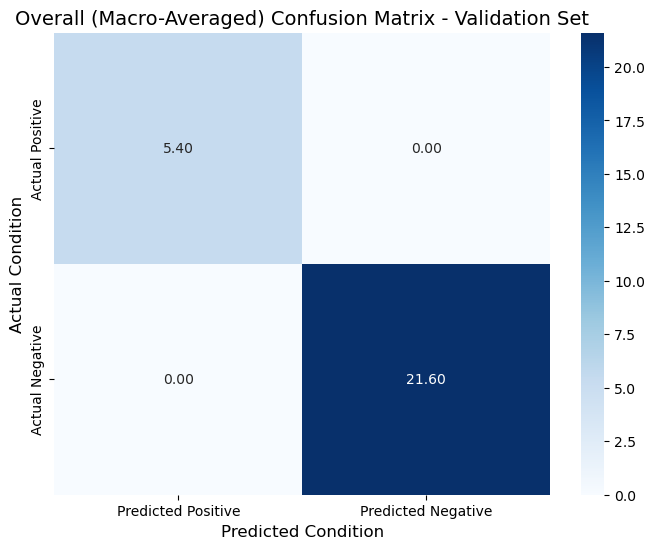


Average TP per class: 5.40
Average FP per class: 0.00
Average TN per class: 21.60
Average FN per class: 0.00


In [11]:
print("Calculat overall performance metrics")

TP = 0
FP = 0
TN = 0
FN = 0

num_classes = 5
total_samples = np.sum(cm) # Total number of samples evaluated

for i in range(num_classes):
    # True Positives (TP): Correctly predicted as class i
    TP_i = cm[i, i]
    
    # False Positives (FP): Incorrectly predicted as class i (sum column i, minus TP_i)
    FP_i = cm[:, i].sum() - TP_i
    
    # False Negatives (FN): Class i was predicted as something else (sum row i, minus TP_i)
    FN_i = cm[i, :].sum() - TP_i
    
    # True Negatives (TN): All samples not in class i, correctly predicted as not class i
    TN_i = total_samples - (TP_i + FP_i + FN_i)
    
    # Sum up for the overall counts (across all classes)
    TP += TP_i
    FP += FP_i
    TN += TN_i
    FN += FN_i

# Calculate the average values per class for the 2x2 matrix
avg_TP = TP / num_classes
avg_FP = FP / num_classes
avg_TN = TN / num_classes
avg_FN = FN / num_classes

# Create the 2x2 matrix data using the *average* values
overall_cm_avg = np.array([[avg_TP, avg_FN], [avg_FP, avg_TN]])

print("--- Generating Overall (Macro-Averaged) 2x2 Confusion Matrix ---")

plt.figure(figsize=(8, 6))
sns.heatmap(overall_cm_avg, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=['Predicted Positive', 'Predicted Negative'],
            yticklabels=['Actual Positive', 'Actual Negative'])

plt.xlabel("Predicted Condition", fontsize=12)
plt.ylabel("Actual Condition", fontsize=12)
plt.title("Overall (Macro-Averaged) Confusion Matrix - Validation Set", fontsize=14)
plt.savefig("confusion_matrix_overall_2x2.png")
plt.show()

print(f"\nAverage TP per class: {avg_TP:.2f}")
print(f"Average FP per class: {avg_FP:.2f}")
print(f"Average TN per class: {avg_TN:.2f}")
print(f"Average FN per class: {avg_FN:.2f}")

--- Loading checkpoint: best_model_checkpoint_fresh.pth ---


C:\Users\chuaw\AppData\Local\Temp\ipykernel_3460\762186184.py:9: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(CHECKPOINT_FILENAME, map_location=devi

Model, weights, and mappings loaded successfully.

--- Evaluating on the Validation set ---


Predicting on Validation: 100%|████████████████████████████████████████████████████████| 26/26 [00:05<00:00,  4.37it/s]


Final Validation Accuracy: 95.35%

--- Generating Confusion Matrix for Validation Set ---


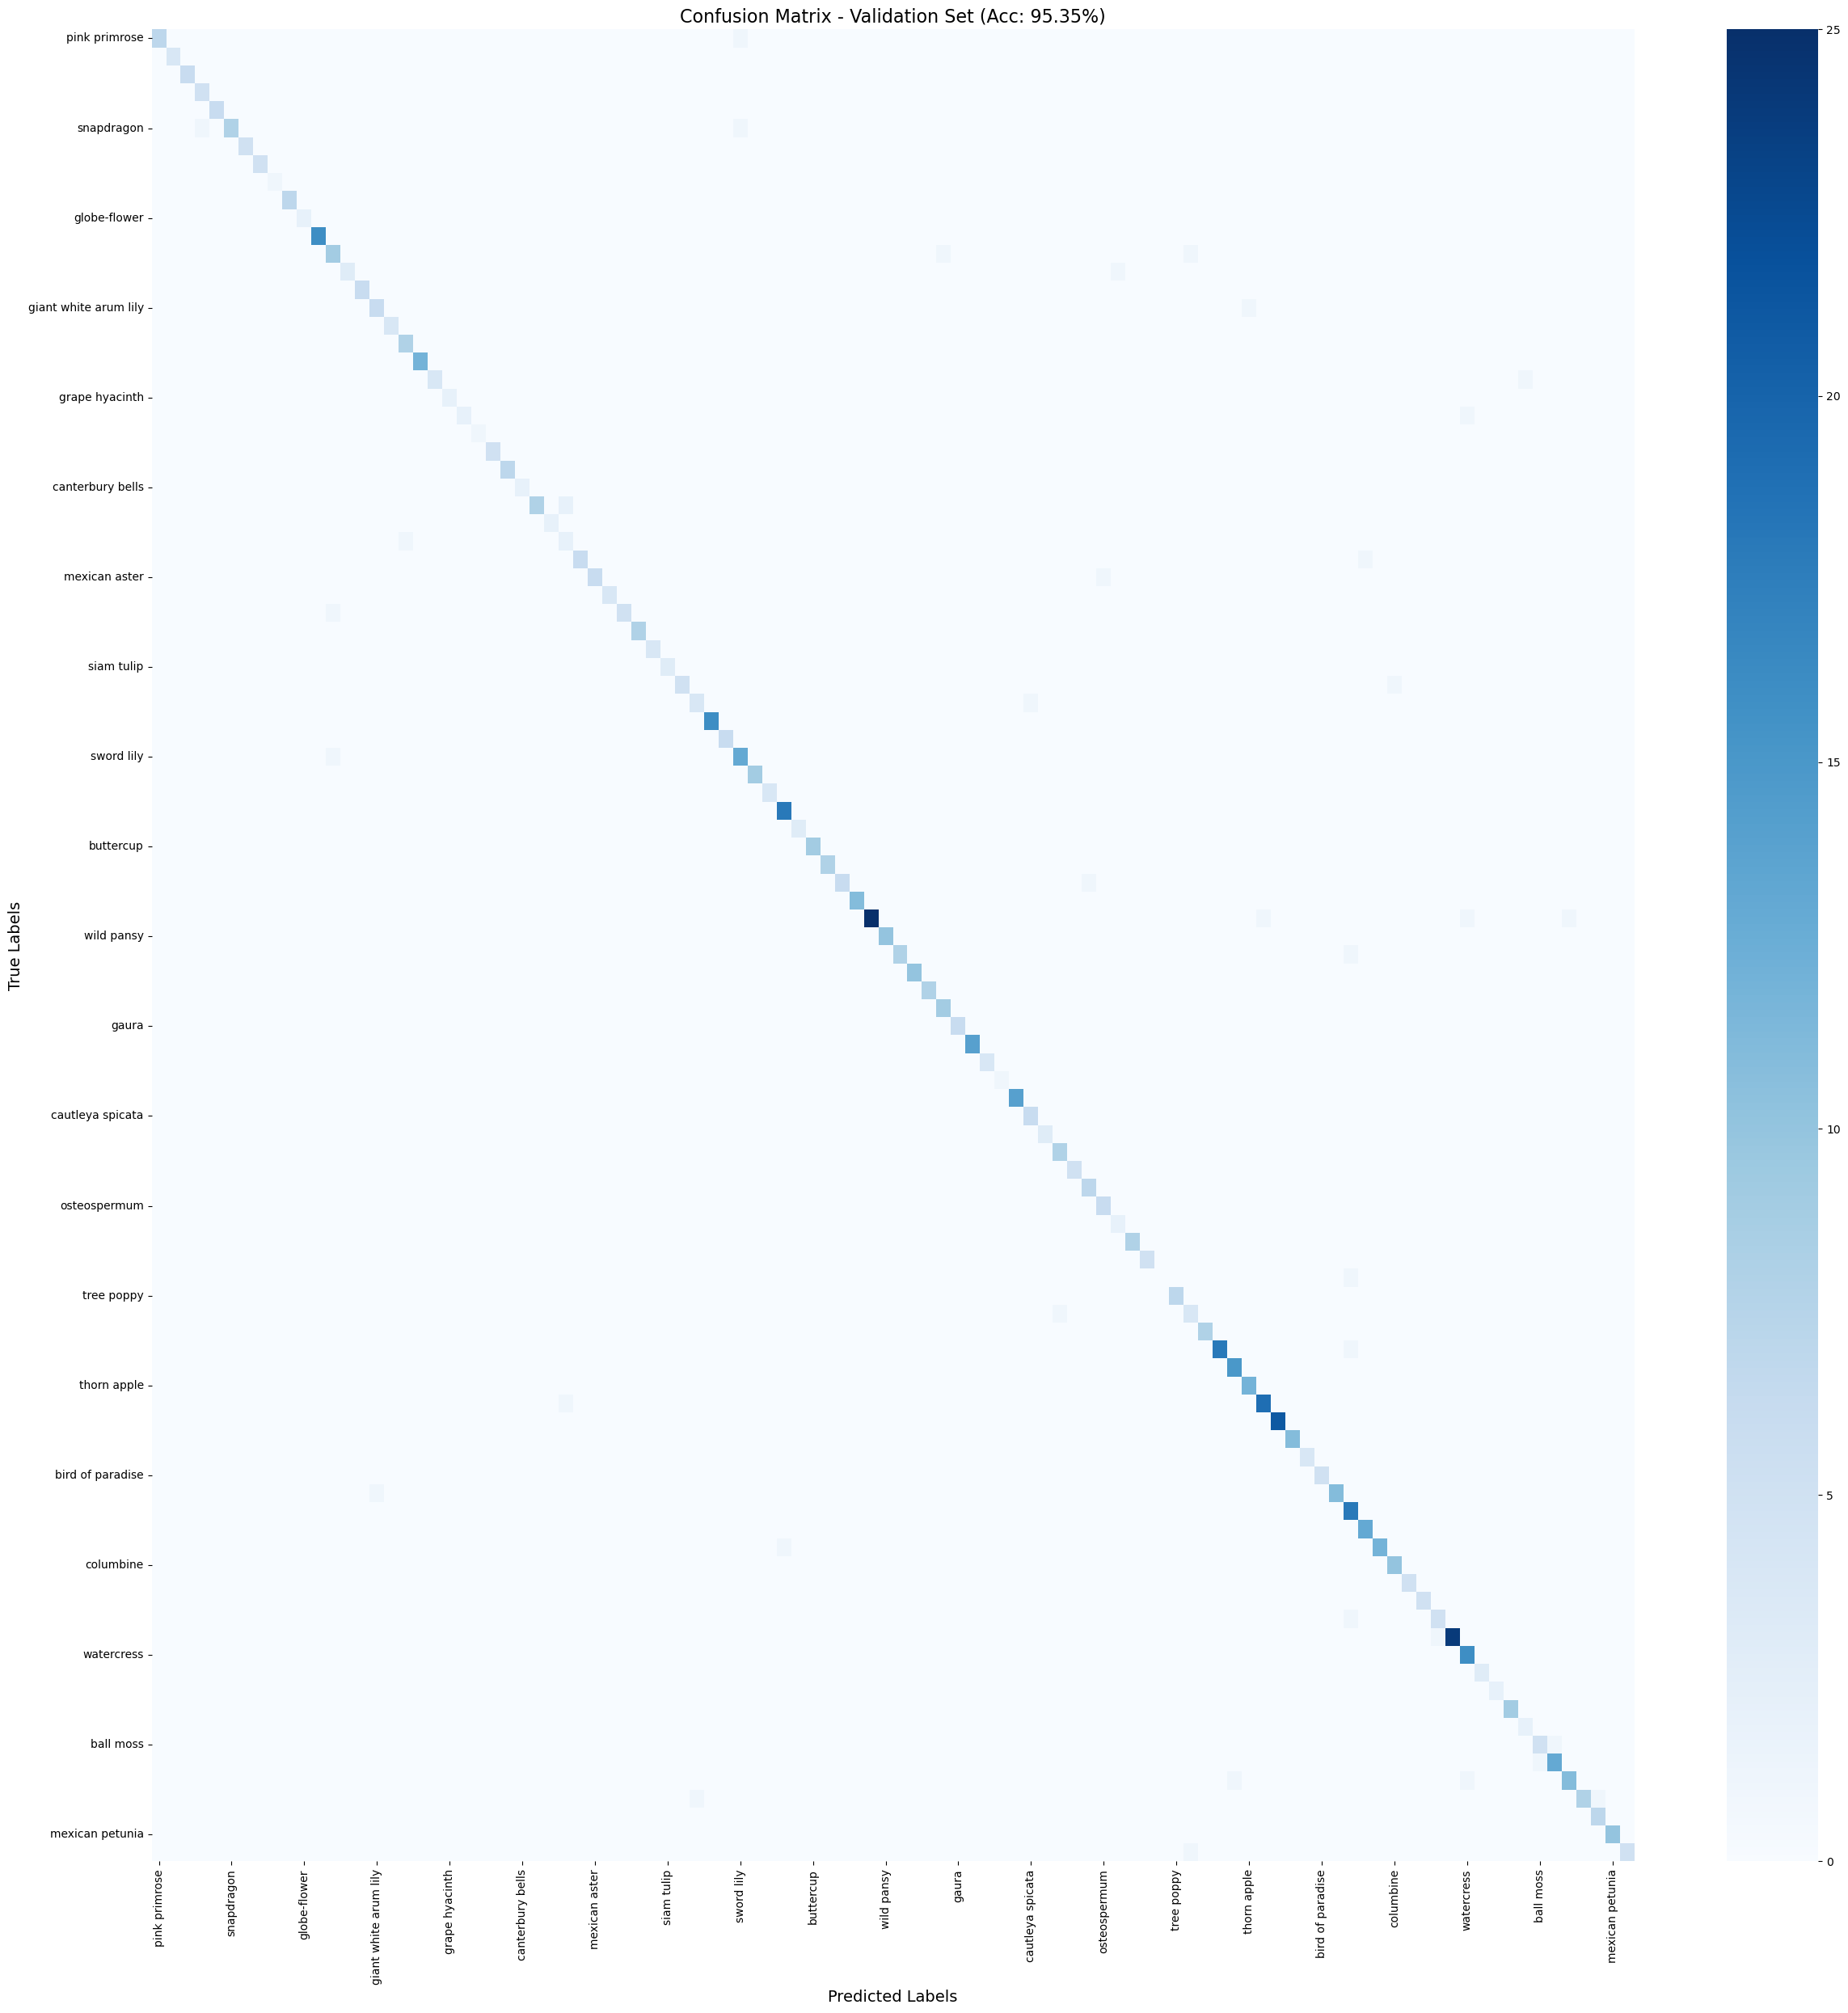

In [12]:
CHECKPOINT_FILENAME = 'best_model_checkpoint_fresh.pth'

# 1 this will Load Model, Weights, and Mappings
print(f"--- Loading checkpoint: {CHECKPOINT_FILENAME} ---")

# this will Load the checkpoint dictionary
try:
    # Use weights_only=True for safety, but check your torch version compatibility
    checkpoint = torch.load(CHECKPOINT_FILENAME, map_location=device) 
except Exception as e:
    print(f"Error loading checkpoint: {e}")

# Re-create the model structure
# Important: Use the same architecture settings (ResNet50, NUM_CLASSES, freeze_backbone)
model = build_model(num_classes=NUM_CLASSES, freeze_backbone=False)

# Load the saved weights (VERY CRITICAL)
model.load_state_dict(checkpoint['model_state_dict'])

# Move model to device (GPU/CPU) and set to evaluation mode
model.to(device)
model.eval()

# Retrieve necessary mappings for reporting
class_to_idx = checkpoint['class_to_idx']
cat_to_name = checkpoint['cat_to_name']
print("Model, weights, and mappings loaded successfully.")


# 2 evaluation function

def evaluate_model(data_loader, dataset_name, checkpoint_filename):
    all_preds = []
    all_labels = []
    correct = 0
    total = 0
    
    print(f"\n--- Evaluating on the {dataset_name} set ---")

    with torch.no_grad():
        for images, labels in tqdm(data_loader, desc=f"Predicting on {dataset_name}"):
            # Note: The test_loader uses a custom TestDataset and may return filenames instead of labels.
            # We assume for *validation* and *testing* that the data loader yields (images, labels).
            # *Assuming* a standard ImageFolder-like structure for this generic function.
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            
            _, preds = torch.max(outputs, 1)
            
            # For accuracy calculation
            total += labels.size(0)
            correct += (preds == labels).sum().item()
            
            # For confusion matrix
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    accuracy = 100 * correct / total
    print(f"Final {dataset_name} Accuracy: {accuracy:.2f}%")
    
    return all_labels, all_preds, accuracy


# --- 3. Evaluate on Validation Set (for sanity check/final report) ---
val_labels, val_preds, val_acc = evaluate_model(valid_loader, "Validation", CHECKPOINT_FILENAME)

# --- 4. Plot Confusion Matrix for Validation Set ---
print("\n--- Generating Confusion Matrix for Validation Set ---")
# Get class names for labeling the plot
class_names = valid_dataset.classes
readable_names = [cat_to_name.get(name, name) for name in class_names]
    
cm = confusion_matrix(val_labels, val_preds)

plt.figure(figsize=(25, 25))
sns.heatmap(cm, annot=False, cmap='Blues', xticklabels=False, yticklabels=False)
plt.xlabel("Predicted Labels", fontsize=14)
plt.ylabel("True Labels", fontsize=14)
plt.title(f"Confusion Matrix - Validation Set (Acc: {val_acc:.2f}%)", fontsize=16)

# To make labels more readable on a large matrix, show every 5th label
tick_spacing = 5
plt.xticks(
    ticks=np.arange(len(readable_names))[::tick_spacing] + 0.5,
    labels=readable_names[::tick_spacing], rotation=90, ha='center'
)
plt.yticks(
    ticks=np.arange(len(readable_names))[::tick_spacing] + 0.5,
    labels=readable_names[::tick_spacing], rotation=0, va='center'
)

plt.tight_layout()
plt.savefig("confusion_matrix_validation_final.png")
plt.show()

# Use actual Test Data for evaluation
now that we have done the first part, its time to use true
<br>Test data!!

<h2>This is to test individual image, can try with any image! just change<br></h2>


--- Prediction for: data\flower_data\my_test\anthurium.jpg ---
   Correct Label: anthurium
Predicted Label: anthurium (Confidence: 99.96%)
       Result: CORRECT


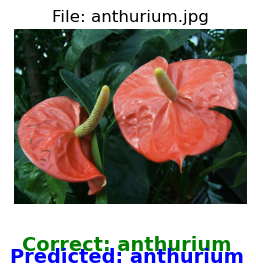

In [13]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# THIS IS FILENAME TO TEST --- IF WANT DIFF image, just change the last anthurium.jpg
filename_to_predict = os.path.join("data", "flower_data", "my_test", "anthurium.jpg")

#get the name from the image
base_name = os.path.basename(filename_to_predict) # "anthurium.jpg"
correct_name = os.path.splitext(base_name)[0]      # "anthurium"

try:
    # 1. Load original image
    image = Image.open(filename_to_predict).convert("RGB")
    
    # 2. Get PREDICTED label from the model

    idx_to_class_folder = {v: k for k, v in class_to_idx.items()}
    #transform
    img_tensor = transform_valid_test_data(image).unsqueeze(0).to(device)
    
    # Run the model
    with torch.no_grad():
        output = model(img_tensor)
        probabilities = torch.nn.functional.softmax(output, dim=1)
        top_prob, top_idx = torch.max(probabilities, 1)
        
        pred_idx = top_idx.item()
        pred_prob = top_prob.item()
        
    # Map the predicted index (0-101) back to a name
    predicted_class_folder = idx_to_class_folder.get(pred_idx, "Unknown Index")
    predicted_name = cat_to_name.get(predicted_class_folder, "Unknown Class")
    
    # 3 Display the results
    # lower is just to incase, the name have human error
    is_correct = (correct_name.lower() == predicted_name.lower())
    prediction_color = "blue" if is_correct else "red"
    
    print(f"--- Prediction for: {filename_to_predict} ---")
    print(f"   Correct Label: {correct_name}")
    print(f"Predicted Label: {predicted_name} (Confidence: {pred_prob*100:.2f}%)")
    print(f"       Result: {'CORRECT' if is_correct else 'INCORRECT'}")

    # Plot the image
    plt.figure(figsize=(3, 3))
    plt.imshow(image)
    plt.title(f"File: {os.path.basename(filename_to_predict)}", fontsize=12)
    plt.axis('off')
    
    # adding text below image
    plt.figtext(0.5, 0.05, f"Correct: {correct_name}", ha="center", fontsize=14, color="green", weight="bold")
    plt.figtext(0.5, 0.01, f"Predicted: {predicted_name}", ha="center", fontsize=14, color=prediction_color, weight="bold")
    
    plt.savefig("single_image_prediction_custom.png")
    plt.show()

except FileNotFoundError:
    print(f"Error: File not found at '{filename_to_predict}'")
    print("Please check the path and try again.")
except Exception as e:
    print(f"An error occurred: {e}")
    print("Make sure you have run Cell 3 and Cell 7 first")

now<br>
# Below code Check every image in my_test folder !!
Blue= Correct Prediction \ Red = Wrong Prediction
<br> (The text shown Below the image)
# The percentage in below images are CONFIDENCE LEVEL OF MODEL

Start predictions for all images inside: data\flower_data\my_test
File: anthurium.jpg | Correct: anthurium | Predicted: anthurium (99.96%)
File: blanket flower.jpg | Correct: blanket flower | Predicted: blanket flower (51.75%)
File: californian poppy.jpg | Correct: californian poppy | Predicted: californian poppy (95.58%)
File: clematis.jpg | Correct: clematis | Predicted: clematis (49.75%)
File: cyclamen.jpg | Correct: cyclamen | Predicted: lotus (52.65%)
File: frangipani.jpg | Correct: frangipani | Predicted: frangipani (99.67%)
File: geranium.jpg | Correct: geranium | Predicted: geranium (99.40%)
File: hibiscus.jpg | Correct: hibiscus | Predicted: hibiscus (88.70%)
File: hippeastrum.jpg | Correct: hippeastrum | Predicted: hippeastrum (88.44%)
File: lotus.jpg | Correct: lotus | Predicted: lotus (99.51%)
File: morning glory.jpg | Correct: morning glory | Predicted: morning glory (84.29%)
File: passion flower.jpg | Correct: passion flower | Predicted: passion flower (99.64%)
File: petu

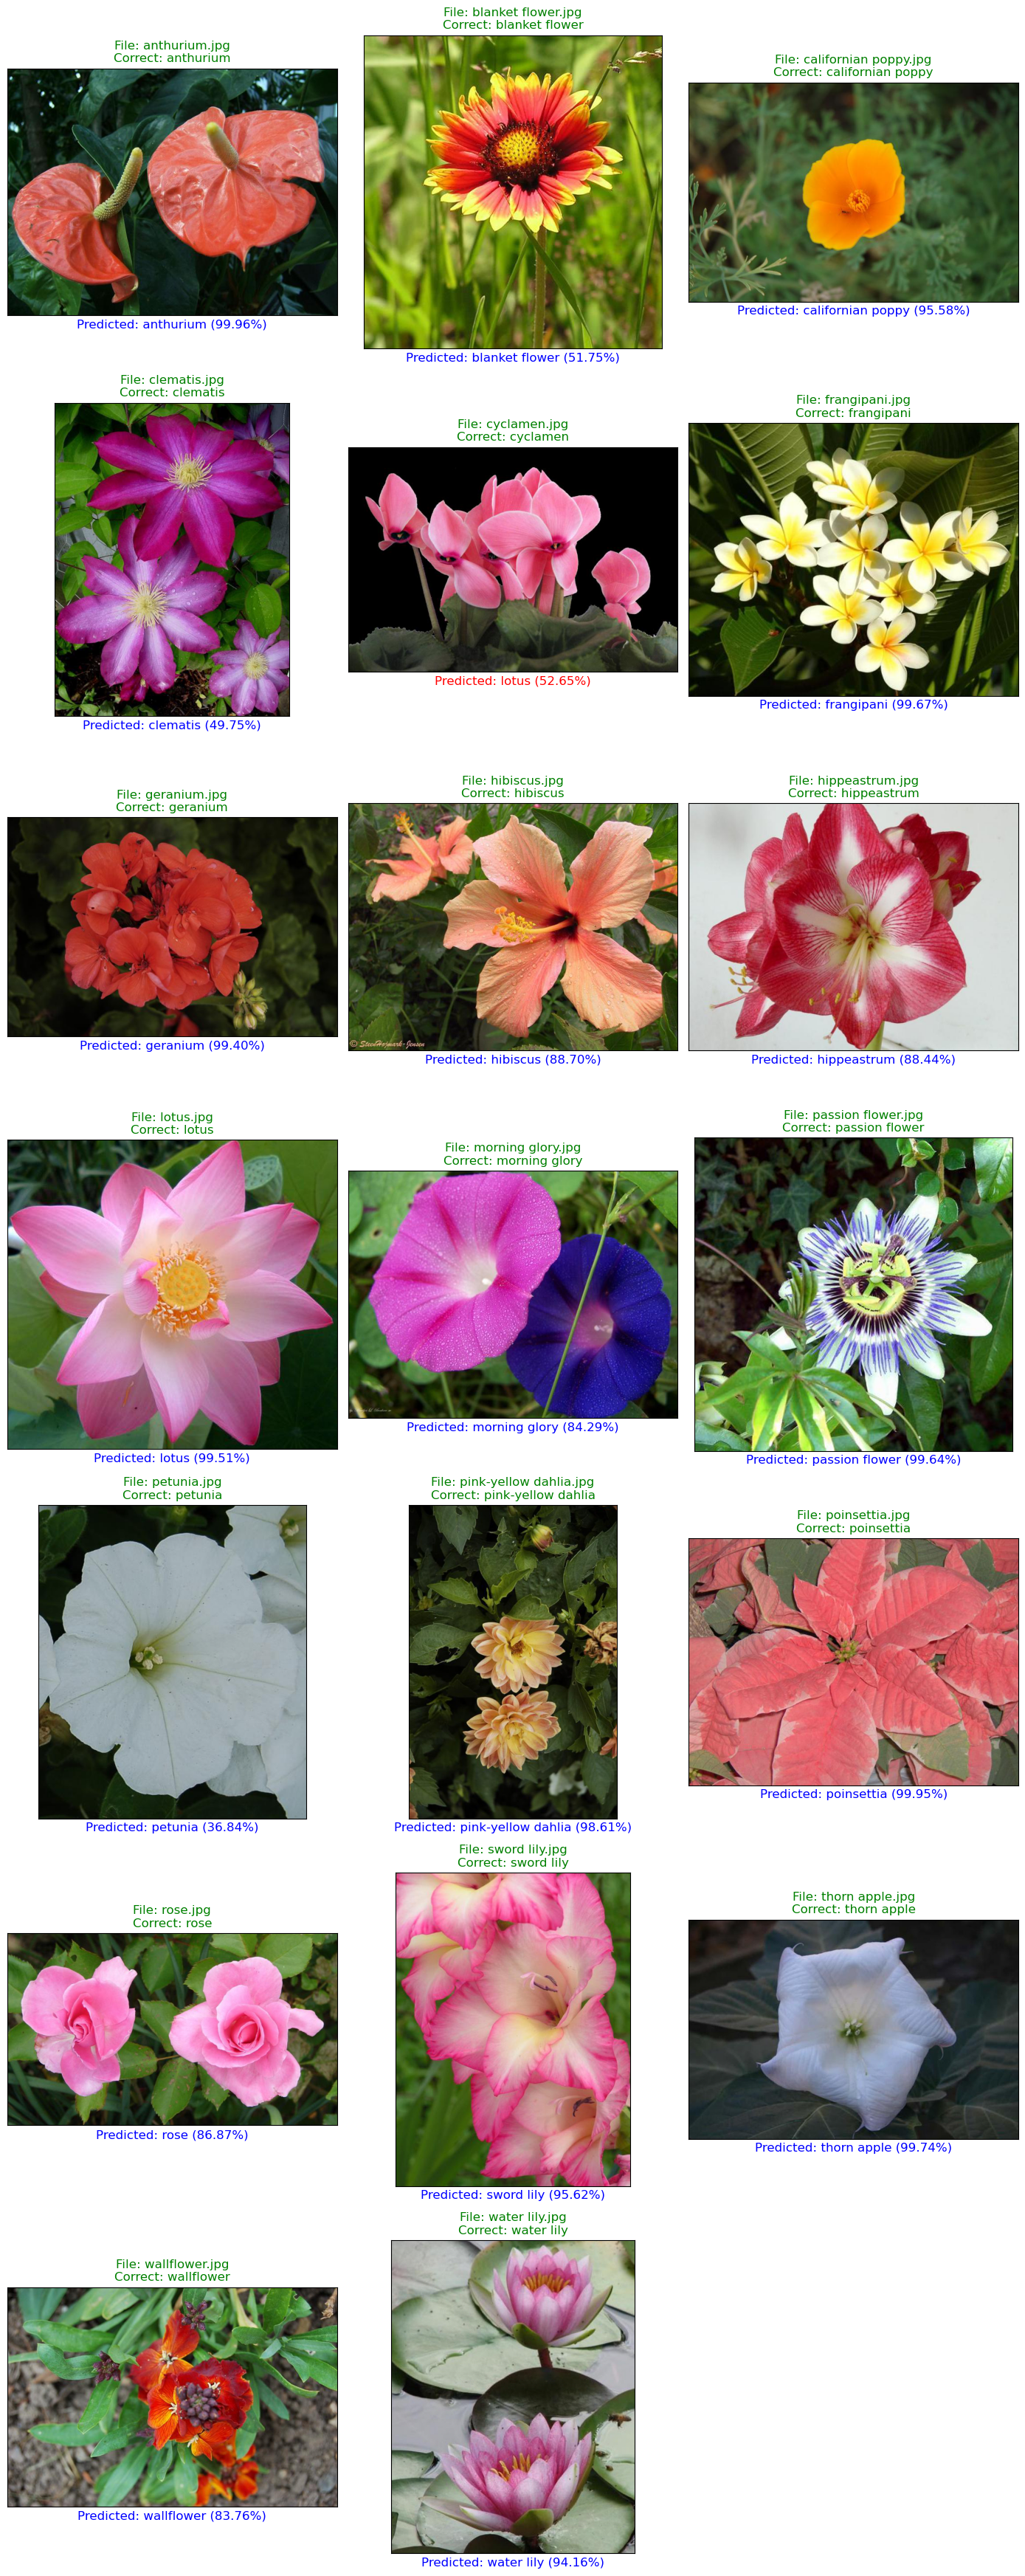

predictions finished. Plot saved to: all_images_grid_prediction.png ---


In [14]:
import math # Needed to calculate the number of rows

# 1. Set directories
test_image_dir = os.path.join("data", "flower_data", "my_test")
output_save_file = "all_images_grid_prediction.png"

print(f"Start predictions for all images inside: {test_image_dir}")

try:
    # 2. Get mappings and list image files 
    # (These variables come from running Cell 3 and Cell 7 first)
    idx_to_class_folder = {v: k for k, v in class_to_idx.items()}
    
    image_files = [f for f in sorted(os.listdir(test_image_dir)) 
                   if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
    
    if not image_files:
        print(f"No image files found in '{test_image_dir}'.")
        raise FileNotFoundError
        
    num_images = len(image_files)
    
    cols = 3
    rows = math.ceil(num_images / cols)
    
    # Set figure size (width, height). 
    fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 5))
    
    axes = axes.flatten()

    # loop through file, then plot
    for i, filename in enumerate(image_files):
        ax = axes[i] # Get the current subplot to draw on
        full_path = os.path.join(test_image_dir, filename)

        # Get Correct Name from filename
        correct_name = os.path.splitext(filename)[0] # "anthurium"
        
        # Load, transform, PREDICT
        image = Image.open(full_path).convert("RGB")
        img_tensor = transform_valid_test_data(image).unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(img_tensor)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            top_prob, top_idx = torch.max(probabilities, 1)
            pred_idx, pred_prob = top_idx.item(), top_prob.item()

        # Map the predicted index (0-101) back to a name
        predicted_class_folder = idx_to_class_folder.get(pred_idx, "Unknown")
        predicted_name = cat_to_name.get(predicted_class_folder, "Unknown Class")
        
        #  6. Print && Plot the result 
        # BLUE FOR CORRECT, RED FOR WRong
        is_correct = (correct_name.lower() == predicted_name.lower())
        prediction_color = "blue" if is_correct else "red"
        
        # Print text output to the console
        print(f"File: {filename} | Correct: {correct_name} | Predicted: {predicted_name} ({pred_prob*100:.2f}%)")
        
        # Plot to the subplot
        ax.imshow(image)
        ax.set_title(f"File: {filename}\nCorrect: {correct_name}", color="green", fontsize=12)
        ax.set_xlabel(f"Predicted: {predicted_name} ({pred_prob*100:.2f}%)", color=prediction_color, fontsize=12)
        ax.set_xticks([])
        ax.set_yticks([])

    # 5. Clean up empty subplots (if got any la)
    # If you have an odd number of images, this hides the last empty plot
    for j in range(num_images, len(axes)):
        axes[j].axis('off')

    # 6. Save and show the final grid image
    plt.tight_layout()
    plt.savefig(output_save_file)
    plt.show()

    print(f"predictions finished. Plot saved to: {output_save_file} ---")

except FileNotFoundError:
    print(f"\nError: Directory not found / no images in '{test_image_dir}'")
except NameError as e:
    print(f"\nAn error occurred: {e}")
    print("\nMake sure you run Cell 3 and Cell 7 first.")
except Exception as e:
    print(f"\nAn unexpected error occurred: {e}")

<h2>Blue= Correct Prediction \\ Red = Wrong Prediction</h2>
# The percentage in above images are CONFIDENCE LEVEL OF MODEL
